# Analysis of Results

Requires the creation of pseudo-labels first (under pseudo_labels/). These pseudo-labels are then to be used for training Faster R-CNN using the SoftTeacher Repository.

In [1]:
import json
import os
import numpy as np
import sys

sys.path.append("../utils")
from plot_layout import set_plot_layout

set_plot_layout(path_to_latex="/home/klees/texlive/2024/bin/x86_64-linux")

results_path = "ssod_logs/" # SoftTeacher training logs (*.log.json), one directory per run

os.makedirs("plots", exist_ok=True)

In [2]:
# Fill in results for comparison
model1 = "Supervised Baseline" # baseline model as implemented by Soft Teacher, trained only on the labeled subset of COCO
model2 = "CSD~\cite{Jeong2019}"
model3 = "STAC~\cite{sohn2020}"
model4 = "Instant Teaching~\cite{zhou2021instant}"
model5 = "Humble Teacher~\cite{tang2021}"
model6 = "Unbiased Teacher~\cite{liu2021}"
model7 = "Soft Teacher~\cite{soft_teacher}"
model8 = "ACRST~\cite{zhang2021semi}"
model9 = "PseCO~\cite{li2022pseco}"
# model10 = "Consistent Teacher" # -> Not directly comparable as it uses RetinaNet instead of Faster R-CNN as the base detector, skipped here
model11 = "Grounding DINO~\cite{liu2023grounding}" # grounding dino pseudo-labels : post-hoc calibration & thresholding at 0.5
model12 = "Ours"

# literature values (training logs are not available): baselines and methods from Table 3 of the Soft Teacher paper
# (https://arxiv.org/abs/2106.09018), ACRST and PseCO from their respective papers
results = {
    model1: {
        "1":{"mAP": 10.00, "std": 0.26}, # keys indicate budget, values in %
        "5":{"mAP": 20.92, "std": 0.15},
        "10":{"mAP": 26.94, "std": 0.111},
        "100":{"mAP": 40.9, "std": 0}, # no std since all the data is used
    },
    model2: {
        "1":{"mAP": 10.51, "std": 0},
        "5":{"mAP": 18.63, "std": 0},
        "10":{"mAP": 22.46, "std": 0},
        "100":{"mAP": 38.82, "std": 0}, # here, also the COCO unlabeled set is used as additional training data
    },
    model3: {
        "1":{"mAP": 13.97, "std": 0.35},
        "5":{"mAP": 24.38, "std": 0.12},
        "10":{"mAP": 28.64, "std": 0.21},
        "100":{"mAP": 39.21, "std": 0}, # here, also the COCO unlabeled set is used as additional training data
    },
    model4: {
        "1":{"mAP": 18.05, "std": 0},
        "5":{"mAP": 26.75, "std": 0},
        "10":{"mAP": 30.40, "std": 0},
        "100":{"mAP": 0, "std": 0}, # here, also the COCO unlabeled set is used as additional training data
    },
    model5: {
        "1":{"mAP": 16.96, "std": 0},
        "5":{"mAP": 27.70, "std": 0},
        "10":{"mAP": 31.61, "std": 0},
        "100":{"mAP": 0, "std": 0}, # here, also the COCO unlabeled set is used as additional training data
    },
    model6: {
        "1":{"mAP": 20.75, "std": 0},
        "5":{"mAP": 28.27, "std": 0},
        "10":{"mAP": 31.50, "std": 0},
        "100":{"mAP": 41.30, "std": 0}, # here, also the COCO unlabeled set is used as additional training data
    },
    model7: {
        "1":{"mAP": 20.46, "std": 0.39},
        "5":{"mAP": 30.74, "std": 0.08},
        "10":{"mAP": 34.04, "std": 0.14},
        "100":{"mAP": 44.5, "std": 0}, # here, also the COCO unlabeled set is used as additional training data
    },
    model8: {
        "1":{"mAP": 26.07, "std": 0},
        "5":{"mAP": 31.35, "std": 0},
        "10":{"mAP": 34.92, "std": 0},
        "100":{"mAP": 42.79, "std": 0}, # here, also the COCO unlabeled set is used as additional training data
    },
    model9: {
        "1":{"mAP": 22.43, "std": 0},
        "5":{"mAP": 32.50, "std": 0},
        "10":{"mAP": 36.06, "std": 0},
        "100":{"mAP": 46.10, "std": 0}, # here, also the COCO unlabeled set is used as additional training data
    }
}


In [3]:
# read the results for our methods from the logs

import glob
# map given names to actual model names in the logs of the Soft Teacher training runs
model_map = {
    model11: "grounding_dino_pseudo_labelsfaster_rcnn_r50_caffe_fpn_coco",
    model12: "bayesian_pls_pseudo_labelsfaster_rcnn_r50_caffe_fpn_coco"
}

def get_results(model_name, results_path):
    if model_name in model_map:
        model_name = model_map[model_name]
    model_results = {}
    for budget in ["1", "5", "10", "100"]:

        if budget == "100":
            pattern = f"{results_path}{model_name}_full_720k/*.log.json" # full config for budget 100%
            matches = sorted(glob.glob(pattern))
            if len(matches) == 0:
                print(f"No log file found for {model_name} with budget {budget}")
                continue
            if len(matches) != 2: # we expect two log files since, the training times out after two days, so we have two jobs
                print(f"Expected exactly 2 files for pattern {pattern}, found {len(matches)}: {matches}")
                continue
            
            with open(matches[-1]) as f: # open the last log file, which contains the final results
                # MMDetection writes one JSON object per line (JSONL), not a single JSON array
                logs = [json.loads(line) for line in f if line.strip()]
                mAP = logs[-1].get("bbox_mAP")
                model_results[budget] = {"mAP": round(100 * mAP, 3), "std": 0}

        else:
            map_values = []
            for fold in [1,2,3,4,5]:

                pattern = f"{results_path}{model_name}_partial_180k/{budget}/{fold}/*.log.json" # partial config for budgets < 100%
                matches = sorted(glob.glob(pattern))
                if len(matches) == 0:
                    print(f"No log file found for {model_name} with budget {budget} and fold {fold}")
                    continue
                if len(matches) > 1:
                    print(f"Expected exactly 1 file for pattern {pattern}, found {len(matches)}: {matches}")
                    continue
                
                with open(matches[0]) as f:
                    # MMDetection writes one JSON object per line (JSONL), not a single JSON array
                    logs = [json.loads(line) for line in f if line.strip()]
                    mAP = logs[-1].get("bbox_mAP")
                    map_values.append(100 * mAP)
        
            if len(map_values) == 0:
                print(f"No results found for {model_name} with budget {budget}")
                model_results[budget] = {"mAP": 0, "std": 0}
            else:
                model_results[budget] = {"mAP": round(np.mean(map_values), 3), "std": round(np.std(map_values), 3)}

    return model_results

In [4]:
for model in model_map.keys():
    results[model] = get_results(model, results_path)

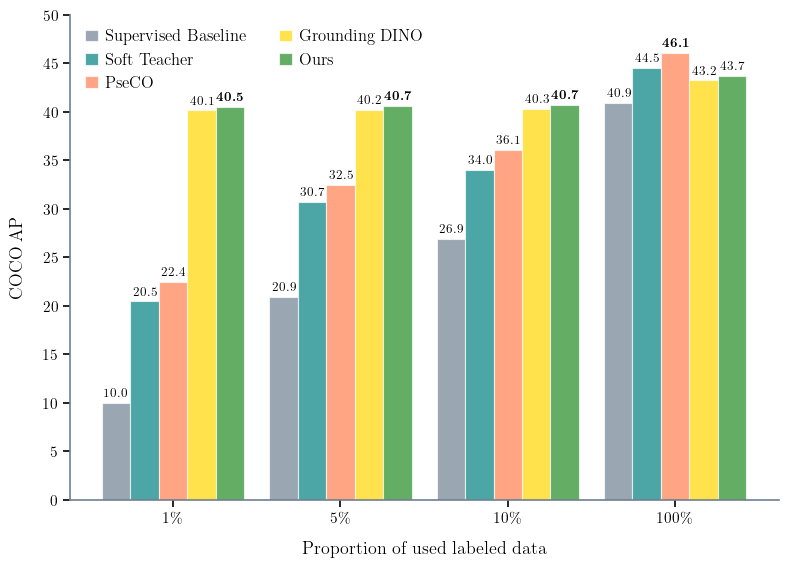

In [5]:
models_to_plot = [model1, model7, model9, model11, model12]  # baseline, Soft Teacher, PseCO, Grounding DINO, Ours
filtered_results = {model: results[model] for model in models_to_plot}


import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 5.8))
ax = plt.gca()

# bar plot results for each model and budget

colors = ["slategray", "teal", "coral", "gold", "forestgreen"]

x_labels = ["1\%", "5\%", "10\%", "100\%"]

x = np.arange(len(x_labels))
n_models = len(filtered_results)
group_width = 0.85 # fraction of the space between ticks taken by one budget group
width = group_width / n_models

# best value per budget (rows: models_to_plot, columns: budgets) is printed in bold
bold_mask = [[0,0,0,0], [0,0,0,0], [0,0,0,1], [0,0,0,0], [1,1,1,0]]

for i, (name, results_dict) in enumerate(filtered_results.items()):
    offset = (i - (n_models - 1) / 2) * width # center the group on its tick
    values = [results_dict[budget]["mAP"] for budget in ["1", "5", "10", "100"]]
    bars = ax.bar(
        x + offset,
        values,
        width,
        label=name.split("~")[0], # remove the citation from the label
        color=colors[i],
        alpha = 0.7,
        edgecolor="white",
        linewidth=0.8,
    )

    # value labels
    j = 0
    for bar, value in zip(bars, values):

        label = f"{value:.1f}"
        if bold_mask[i][j]:
            # with text.usetex=True, matplotlib ignores fontweight for tex-rendered
            # text, so bold must be applied via an explicit LaTeX command instead
            label = f"\\textbf{{{label}}}"

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.4,
            label,
            ha="center",
            va="bottom",
            fontsize=9.25,
        )
        j+=1

# ----------------------------------------------------------------------

ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=11)

ax.set_xlabel(
    "Proportion of used labeled data",
    fontsize=13,
    labelpad=12,
)

ax.set_ylabel(
    "COCO AP",
    fontsize=13,
    labelpad=12,
)

ax.set_ylim(0, 50)

ax.set_yticks(np.arange(0, 51, 5))
ax.tick_params(axis="y", labelsize=11)

ax.legend(
    loc="upper left",
    frameon=False,
    ncols=2,
    fontsize=12,
    handlelength=0.8,
    handletextpad=0.4,
)

# Clean appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)

ax.tick_params(width=1.2, length=5)

plt.tight_layout()

plt.savefig("plots/SSOD_benchmark_results.pdf", dpi=600, bbox_inches="tight")
plt.show()

In [6]:
# generate latex table for the paper

def generate_latex_table(results):
    table = "\\begin{table}[htbp]\n"
    table += "\\centering\n"
    table += "\\resizebox{\\linewidth}{!}{\n"
    table += "\\begin{tabular}{llllc}\n"
    table += "\\toprule\n"
    table += "Method & 1\\% & 5\\% & 10\\% & 100\\% \\\\\n"
    table += "\\midrule\n"
    class BoldFloat(float):
        def __new__(cls, value, bold=False):
            obj = float.__new__(cls, value)
            obj.bold = bold
            return obj

        def __format__(self, format_spec):
            formatted = format(float(self), format_spec)
            return f"\\textbf{{{formatted}}}" if self.bold else formatted

    budgets = ["1", "5", "10", "100"]
    max_per_budget = {
        b: max(float(results[m][b]["mAP"]) for m in results)
        for b in budgets
    }

    for method, results_dict in results.items():
        for b in budgets:
            val = float(results_dict[b]["mAP"])
            results_dict[b]["mAP"] = BoldFloat(
                val, bold=np.isclose(val, max_per_budget[b])
            )
        row = f"{method} "
        for budget in ["1", "5", "10", "100"]:
            mAP = results_dict[budget]["mAP"]
            std = results_dict[budget]["std"]
            if budget == "100":
                if mAP > 0:
                    row += f"& {mAP:.2f} " # no std for 100% budget
                else:
                    row += "& - " # no results for 100% budget
            else:
                if std > 0:
                    row += f"& {mAP:.2f} $\\pm$ {std:.2f} " # round consistently to 2 decimal places
                else:
                    row += f"& {mAP:.2f} " # no std available
                
        row += "\\\\\n"
        table += row
    table += "\\bottomrule\n"
    table += "\\end{tabular}\n"
    table += "}\n"
    table += """\\caption{
    Comparison of different semi-supervised object detection methods on COCO.
    The results are reported for different fractions of annotated training data in terms of mean average precision (AP).
    For annotation budgets below 100\%, results are averaged over 5 folds of annotated data and standard deviation is reported, following the evaluation protocol of~\cite{sohn2020}.
    We list the numbers for existing methods as reported by~\cite{soft_teacher} and~\cite{wang2023} where standard deviations are not always given.
    }\n"""
    table += "\\label{tab:ssod_results_coco}\n"
    table += "\\end{table}\n"
    return table

print(generate_latex_table(results))

\begin{table}[htbp]
\centering
\resizebox{\linewidth}{!}{
\begin{tabular}{llllc}
\toprule
Method & 1\% & 5\% & 10\% & 100\% \\
\midrule
Supervised Baseline & 10.00 $\pm$ 0.26 & 20.92 $\pm$ 0.15 & 26.94 $\pm$ 0.11 & 40.90 \\
CSD~\cite{Jeong2019} & 10.51 & 18.63 & 22.46 & 38.82 \\
STAC~\cite{sohn2020} & 13.97 $\pm$ 0.35 & 24.38 $\pm$ 0.12 & 28.64 $\pm$ 0.21 & 39.21 \\
Instant Teaching~\cite{zhou2021instant} & 18.05 & 26.75 & 30.40 & - \\
Humble Teacher~\cite{tang2021} & 16.96 & 27.70 & 31.61 & - \\
Unbiased Teacher~\cite{liu2021} & 20.75 & 28.27 & 31.50 & 41.30 \\
Soft Teacher~\cite{soft_teacher} & 20.46 $\pm$ 0.39 & 30.74 $\pm$ 0.08 & 34.04 $\pm$ 0.14 & 44.50 \\
ACRST~\cite{zhang2021semi} & 26.07 & 31.35 & 34.92 & 42.79 \\
PseCO~\cite{li2022pseco} & 22.43 & 32.50 & 36.06 & \textbf{46.10} \\
Grounding DINO~\cite{liu2023grounding} & 40.14 $\pm$ 0.11 & 40.19 $\pm$ 0.08 & 40.30 $\pm$ 0.10 & 43.24 \\
Ours & \textbf{40.50} $\pm$ 0.23 & \textbf{40.65} $\pm$ 0.11 & \textbf{40.74} $\pm$ 0.08 & 4

## Training Logs (mAP curves)

In [7]:
fold = 1

perc_labeled = 10

model1 = f"Supervised Baseline ({perc_labeled}\%)" # baseline model
model2 = f"Bayesian PLS ({perc_labeled}\%)" # Faster R-CNN trained with Bayesian PLS pseudo-labels

# map given names to actual model names in the logs of the Soft Teacher training runs
model_map = {
    model1: "faster_rcnn_r50_caffe_fpn_coco_partial_180k",
    model2: model_map[model12] + "_partial_180k"
}

results = {
    model1: {},
    model2: {}
}


In [8]:
import glob
import matplotlib.pyplot as plt

def get_results(model_name, fold, perc_labeled):
    pattern = f"{results_path}{model_name}/{perc_labeled}/{fold}/*.log.json"
    matches = sorted(glob.glob(pattern))
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected exactly 1 file for pattern {pattern}, found {len(matches)}: {matches}")

    with open(matches[0]) as f:
        # MMDetection writes one JSON object per line (JSONL), not a single JSON array
        logs = [json.loads(line) for line in f if line.strip()]

    return logs

logs = get_results(model_map[model1], fold, perc_labeled)
print(f"Loaded {len(logs)} log entries  "
      f"({sum(l.get('mode')=='train' for l in logs)} train, "
      f"{sum(l.get('mode')=='val' for l in logs)} val)")

Loaded 3646 log entries  (3600 train, 45 val)


  Supervised Baseline (10\%): 45 val checkpoints
  Bayesian PLS (10\%): 45 val checkpoints


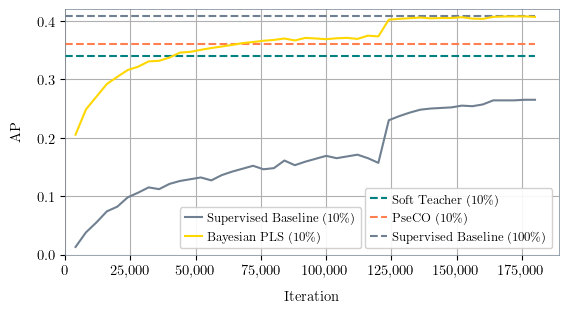

In [9]:
# Load logs for every model in model_map
all_logs = {}
for model_key, model_name in model_map.items():
    try:
        all_logs[model_key] = get_results(model_name, fold, perc_labeled)
        val_entries = sum(l.get("mode") == "val" for l in all_logs[model_key])
        print(f"  {model_key}: {val_entries} val checkpoints")
    except FileNotFoundError as e:
        print(f"  Warning – {e}")

# ── mAP comparison across all models ────────────────────────────────────────────
fig, ax = plt.subplots()

# literature / full-data reference values (dashed lines)
ref_handles = [
    ax.hlines(y=0.3404, xmin=0, xmax=180000, color='teal', linestyle='--', linewidth=1.5, label='Soft Teacher (10\%)'),
    ax.hlines(y=0.3606, xmin=0, xmax=180000, color='coral', linestyle='--', linewidth=1.5, label='PseCO (10\%)'),
    ax.hlines(y=0.4090, xmin=0, xmax=180000, color='slategray', linestyle='--', linewidth=1.5, label='Supervised Baseline (100\%)'),
]

curve_handles = []
for model_key, model_logs in all_logs.items():
    color = "gold" if model_key == model2 else "slategray"
    val_logs = [l for l in model_logs if l.get("mode") == "val"]
    iters = [l["iter"]     for l in val_logs]
    mAP   = [l["bbox_mAP"] for l in val_logs]
    line, = ax.plot(iters, mAP, lw=1.5, label=model_key, color=color)
    curve_handles.append(line)

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.set_xlabel("Iteration")
ax.set_ylabel("AP")
ax.xaxis.set_major_formatter(lambda x, pos: f"{int(x):,}")

# separate legends for reference lines and training curves; add_artist() keeps the
# first legend when the second ax.legend() call is made
ref_legend = ax.legend(handles=ref_handles, loc='lower right', handlelength=1.4,
                        handletextpad=0.4, fontsize=9, framealpha=0.9)
ax.add_artist(ref_legend)
ax.legend(handles=curve_handles, loc='lower left', bbox_to_anchor=(0.22, 0.0),
          handlelength=1.4, handletextpad=0.4, fontsize=9, framealpha=0.9)
ax.grid(True)

ax.set_ylim(bottom=0, top=0.42)

plt.tight_layout()

plt.savefig("plots/SSOD_benchmark_results_training_curves.pdf", dpi=300, bbox_inches="tight")
plt.show()